# Prétraitement et visualisation des données fNIRS, ECG, RSP



## 1. Imports et paramètres

In [28]:
import os
import re
import ast
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from tqdm import tqdm

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.signal import butter, filtfilt, sosfiltfilt
from scipy.interpolate import interp1d
from scipy.stats import skew, kurtosis

import neurokit2 as nk

warnings.filterwarnings("ignore")


In [30]:
# ============================================================
# FRÉQUENCES
# ============================================================
FS_FNIRS = 25
FS_ECG   = 250
FS_RSP   = 18

COL_TIME_SH = "SensorHubTimestampInMillisecond"

# ============================================================
# CHEMINS À ADAPTER
# ============================================================
DOSSIER_SENSORHUB = Path(
    r"\\fss.ulaval.ca\partages\FSS\Départements\Psychologie"
    r"\Laboratoires de recherche\Attention\Neurostimulation\Data\SensorHub2"
)

CHEMIN_SYNTHESE = DOSSIER_SENSORHUB / "Synthese_Dossiers.xlsx"

DOSSIER_OXYSOFT = Path(
    r"\\fss.ulaval.ca\partages\FSS\Départements\Psychologie"
    r"\Laboratoires de recherche\Attention\Neurostimulation\Data\Neurostimulation_TDCS_csv"
)

# Feuille principale créée précédemment, avec :
# Source_pre, Source_post, Pré - Enlèvement du casque
CHEMIN_TEMPS = Path("Feuilles_de_Temps_TDCS_timestamps_ms.xlsx")

# Excel alternatif pour les timestamps POST SensorHub des biosignaux
# seulement utile si Source_post == "oxysoft" mais ECG/RSP existent en SensorHub.
CHEMIN_TEMPS_BIO_POST = Path("Feuille_de_temps_only_SensorHub.xlsx")

# ============================================================
# SORTIES
# ============================================================
DOSSIER_PRETRAITES =  Path(
    r"\\fss.ulaval.ca\partages\FSS\Départements\Psychologie"
    r"\Laboratoires de recherche\Attention\Neurostimulation\Data\Données Prétraitées")
DOSSIER_PRETRAITES.mkdir(parents=True, exist_ok=True)

FICH_NIRS_OUT = "BriteLiteFrontalTDDRFiltered_v3.csv"
FICH_ECG_OUT  = "BioEcgPreprocessed_v3.csv"
FICH_RSP_OUT  = "BioBreathingPreprocessed_v3.csv"

# ============================================================
# OXYSOFT
# ============================================================
SKIPROWS_OXYSOFT = 62

NOMS_COLONNES_OXYSOFT = [
    "Sample",
    "Rx1_Tx1_O2Hb", "Rx1_Tx1_HHb",
    "Rx1_Tx3_O2Hb", "Rx1_Tx3_HHb",
    "Rx2_Tx1_O2Hb", "Rx2_Tx1_HHb",
    "Rx2_Tx3_O2Hb", "Rx2_Tx3_HHb",
    "Rx3_Tx4_O2Hb", "Rx3_Tx4_HHb",
    "Rx3_Tx5_O2Hb", "Rx3_Tx5_HHb",
    "Rx4_Tx4_O2Hb", "Rx4_Tx4_HHb",
    "Rx4_Tx5_O2Hb", "Rx4_Tx5_HHb",
    "Event",
    "Event_text"
]


In [24]:
def dossier_sortie_participant(num):
    path = DOSSIER_PRETRAITES / f"P{int(num):02d}"
    path.mkdir(parents=True, exist_ok=True)
    return path


## 2. Chargement des feuilles de temps

In [7]:
def extraire_num_participant(x):
    if pd.isna(x):
        return pd.NA
    m = re.search(r"\d+", str(x))
    return int(m.group()) if m else pd.NA


def charger_feuille_temps(path):
    df = pd.read_excel(path)
    df.columns = df.columns.str.strip()

    df["Participant"] = df["Participant"].apply(extraire_num_participant).astype("Int64")

    for col in ["Source_pre", "Source_post"]:
        if col in df.columns:
            df[col] = df[col].astype(str).str.lower().str.strip()

    cols_meta = ["Participant", "Date", "Source_pre", "Source_post", "Notes"]
    cols_temps = [c for c in df.columns if c not in cols_meta]

    df[cols_temps] = df[cols_temps].apply(pd.to_numeric, errors="coerce")

    return df.dropna(subset=["Participant"]).copy()


df_temps = charger_feuille_temps(CHEMIN_TEMPS)

if CHEMIN_TEMPS_BIO_POST.exists():
    df_temps_bio_post = charger_feuille_temps(CHEMIN_TEMPS_BIO_POST)
else:
    df_temps_bio_post = pd.DataFrame()
    print("⚠️ Feuille BIO POST absente : les phases post ECG/RSP utiliseront df_temps par défaut.")

df_temps.head()


,Participant,Date,Pré - Oxysoft – Start measurement,SensorHub – Start processing,Pré - Début B1,Pré - Début P1,Pré - Fin P1,Pré - Début O1,Pré - Fin O1,Pré - Début O2,...,durée o1,durée questionnaire 2,durée o2,durée questionnaire 3 / enlèvement casque,durée questionnaire 3,durée pratique t,durée ant1,durée questionnaire 4,durée ant2,durée post pvt
0,1,2025-03-24,0.0,2.257400e+05,4.514800e+05,5.030400e+05,1.763040e+06,2.636200e+06,3.356200e+06,3.465920e+06,...,720000.0,109720.0,660000.0,30000.0,239200.0,68960.0,480000.0,141760.0,480000.0,1200000.0
1,2,2025-03-25,NaN,1.742930e+12,1.742930e+12,1.742930e+12,1.742931e+12,1.742933e+12,1.742933e+12,1.742934e+12,...,720000.0,159835.0,720000.0,30000.0,346066.0,75040.0,660000.0,-60494.0,660000.0,1260000.0
2,3,2025-03-27,NaN,1.743095e+12,1.743095e+12,1.743095e+12,1.743096e+12,1.743097e+12,1.743098e+12,1.743098e+12,...,720000.0,178553.0,720000.0,30000.0,263922.0,65318.0,420000.0,160153.0,420000.0,1200000.0
3,4,2025-03-27,NaN,1.743109e+12,1.743109e+12,1.743109e+12,1.743110e+12,1.743112e+12,1.743112e+12,1.743113e+12,...,720000.0,125722.0,720000.0,30000.0,155424.0,65075.0,540000.0,87826.0,420000.0,1200000.0
4,5,2025-03-28,NaN,1.743167e+12,1.743167e+12,1.743167e+12,1.743168e+12,1.743169e+12,1.743170e+12,1.743170e+12,...,720000.0,77718.0,720000.0,30000.0,277715.0,75418.0,450000.0,122194.0,435000.0,1260000.0


# 3. Synthèse chemins participants

In [9]:
df_synthese = pd.read_excel(CHEMIN_SYNTHESE)
df_synthese.columns = df_synthese.columns.str.strip()
df_synthese["Participant"] = df_synthese["Participant"].apply(extraire_num_participant).astype("Int64")

df_synthese = (
    df_synthese
    .dropna(subset=["Participant", "Chemin complet"])
    .drop_duplicates("Participant", keep="last")
    .set_index("Participant")
)

dico_dossiers_sh = df_synthese["Chemin complet"].to_dict()


In [10]:
def trouver_fichier_oxysoft(num, phase):
    num = int(num)
    phase = phase.lower()

    candidats = [
        DOSSIER_OXYSOFT / f"{num:02d}_{phase}.csv",
        DOSSIER_OXYSOFT / f"{num}_{phase}.csv",
    ]

    for p in candidats:
        if p.exists():
            return p

    return None


## 4. Phases utilisées pour les features

In [11]:
PHASES_FEATURES = {
    "Pré - Baseline":  ("Pré - Début B1", "Pré - Début P1"),
    "Pré - PVT":       ("Pré - Début P1", "Pré - Fin P1"),
    "Pré - OpenMATB1": ("Pré - Début O1", "Pré - Fin O1"),
    "Pré - OpenMATB2": ("Pré - Début O2", "Pré - Fin O2"),
    "Pré - ANT1":      ("Pré - Début A1", "Pré - Fin A1"),
    "Pré - ANT2":      ("Pré - Début A2", "Pré - Fin A2"),

    "Post - Baseline": ("Post - Début B1", "Post - Début P1"),
    "Post - PVT":      ("Post - Début P1", "Post - Fin P1"),
}


def _valid_pair(a, b):
    return pd.notna(a) and pd.notna(b) and float(a) < float(b)


def dico_phases_depuis_df(df):
    dico = {}

    for _, row in df.iterrows():
        num = int(row["Participant"])
        dico[num] = {}

        for phase, (c0, c1) in PHASES_FEATURES.items():
            if c0 in df.columns and c1 in df.columns and _valid_pair(row[c0], row[c1]):
                dico[num][phase] = (float(row[c0]), float(row[c1]))

    return dico


# Pour fNIRS : toujours la feuille principale.
dico_phases_fnirs = dico_phases_depuis_df(df_temps)


### Phases ECG/RSP

In [13]:
def construire_dico_phases_bio(df_main, df_bio_post):
    dico = {}

    if not df_bio_post.empty:
        df_bio_post_idx = df_bio_post.set_index("Participant")
    else:
        df_bio_post_idx = pd.DataFrame()

    for _, row in df_main.iterrows():
        num = int(row["Participant"])
        source_post = str(row.get("Source_post", "")).lower().strip()

        dico[num] = {}

        # PRE : toujours depuis la feuille principale
        for phase, (c0, c1) in PHASES_FEATURES.items():
            if not phase.startswith("Pré"):
                continue

            if c0 in row.index and c1 in row.index and _valid_pair(row[c0], row[c1]):
                dico[num][phase] = (float(row[c0]), float(row[c1]))

        # POST : autre feuille si Source_post oxysoft et autre feuille disponible
        row_post = row

        if source_post == "oxysoft" and not df_bio_post_idx.empty and num in df_bio_post_idx.index:
            row_post = df_bio_post_idx.loc[num]

        for phase, (c0, c1) in PHASES_FEATURES.items():
            if not phase.startswith("Post"):
                continue

            if c0 in row_post.index and c1 in row_post.index and _valid_pair(row_post[c0], row_post[c1]):
                dico[num][phase] = (float(row_post[c0]), float(row_post[c1]))

    return dico


dico_phases_bio = construire_dico_phases_bio(df_temps, df_temps_bio_post)


## 5. Lecture fNIRS SensorHub / Oxysoft

In [16]:
def canal_oxy_to_sh(col):
    return (
        col.replace("_", "")
           .replace("O2Hb", "O2HB")
           .replace("HHb", "HHB")
    )


def lire_fnirs_oxysoft(path_csv):
    encodages = ["utf-8-sig", "cp1252", "latin1"]

    for enc in encodages:
        try:
            df = pd.read_csv(
                path_csv,
                skiprows=SKIPROWS_OXYSOFT,
                names=NOMS_COLONNES_OXYSOFT,
                sep=";",
                engine="python",
                encoding=enc
            )
            break
        except Exception as e:
            last_err = e
            df = None

    if df is None:
        raise ValueError(f"Impossible de lire {path_csv.name} : {last_err}")

    df.columns = df.columns.str.strip()

    df["Sample"] = pd.to_numeric(df["Sample"], errors="coerce")
    sample0 = df["Sample"].dropna().iloc[0]
    df["Time_ms"] = ((df["Sample"] - sample0) / FS_FNIRS) * 1000

    # Renommage vers format SensorHub : Rx1Tx1O2HB, Rx1Tx1HHB...
    rename = {}
    for c in df.columns:
        if "Rx" in c and ("O2Hb" in c or "HHb" in c):
            rename[c] = canal_oxy_to_sh(c)

    df = df.rename(columns=rename)

    keep = ["Time_ms"] + [
        c for c in df.columns
        if c.upper().endswith("O2HB") or c.upper().endswith("HHB")
    ]

    return df[keep].apply(pd.to_numeric, errors="coerce")


def lire_fnirs_sensorhub(dossier):
    path = Path(dossier) / "BriteLiteFrontalRaw.csv"

    if not path.exists():
        raise FileNotFoundError(path)

    df = pd.read_csv(path, sep=None, engine="python")
    df.columns = df.columns.str.strip()

    df[COL_TIME_SH] = pd.to_numeric(
        df[COL_TIME_SH].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

    df = df.rename(columns={COL_TIME_SH: "Time_ms"})

    keep = ["Time_ms"] + [
        c for c in df.columns
        if c.upper().endswith("O2HB") or c.upper().endswith("HHB")
    ]

    return df[keep].apply(pd.to_numeric, errors="coerce")


## 6. Prétraitement fNIRS : TDDR + filtre

In [17]:
def tddr(signal, sample_rate, cutoff=0.5, order=3):
    signal = np.asarray(signal, dtype=float)

    signal_mean = np.nanmean(signal)
    s = signal - signal_mean

    Fc = cutoff * 2 / sample_rate

    if Fc < 1:
        fb, fa = butter(order, Fc)
        signal_low = filtfilt(fb, fa, s)
    else:
        signal_low = s

    signal_high = s - signal_low

    tune = 4.685
    D = np.sqrt(np.finfo(float).eps)
    mu = np.inf

    deriv = np.diff(signal_low)
    w = np.ones_like(deriv)

    for _ in range(50):
        mu0 = mu
        mu = np.sum(w * deriv) / np.sum(w)

        dev = np.abs(deriv - mu)
        sigma = 1.4826 * np.median(dev)

        if sigma == 0:
            break

        r = dev / (tune * sigma)
        w = ((1 - r**2) * (r < 1)) ** 2

        if abs(mu - mu0) < D * max(abs(mu), abs(mu0)):
            break

    new_deriv = w * (deriv - mu) + mu
    signal_low_corr = np.cumsum(np.insert(new_deriv, 0, 0.0))

    return signal_low_corr + signal_high + signal_mean


def bandpass_fnirs(signal, fs=FS_FNIRS, lowcut=0.01, highcut=0.5):
    nyq = fs / 2

    b_hp, a_hp = butter(3, lowcut / nyq, btype="high")
    y = filtfilt(b_hp, a_hp, signal)

    b_lp, a_lp = butter(5, highcut / nyq, btype="low")
    y = filtfilt(b_lp, a_lp, y)

    return y


def filtrer_segment_fnirs(seg, min_len=100):
    seg = seg.copy()

    cols = [
        c for c in seg.columns
        if c.upper().endswith("O2HB") or c.upper().endswith("HHB")
    ]

    if len(seg) < min_len:
        return None

    for c in cols:
        x = seg[c].to_numpy(dtype=float)

        if np.isnan(x).mean() > 0.2:
            continue

        x = pd.Series(x).interpolate(limit_direction="both").to_numpy()
        x = tddr(x, sample_rate=FS_FNIRS)
        x = bandpass_fnirs(x, fs=FS_FNIRS)

        seg[c] = x

    return seg


In [25]:
def traiter_fnirs_participant(row, min_len=100):
    num = int(row["Participant"])
    source_pre = str(row["Source_pre"]).lower().strip()
    source_post = str(row["Source_post"]).lower().strip()

    parties = []

    # ========================================================
    # PRE
    # ========================================================
    if source_pre == "sensorhub":
        dossier = dico_dossiers_sh.get(num)

        if dossier is None:
            print(f"⚠️ P{num} : dossier SensorHub absent pour PRE")
        else:
            try:
                df = lire_fnirs_sensorhub(dossier)

                t0 = row["SensorHub – Start processing"]
                t1 = row["Pré - Enlèvement du casque"]

                if _valid_pair(t0, t1):
                    seg = df[(df["Time_ms"] >= t0) & (df["Time_ms"] <= t1)].copy()
                    seg["Bloc"] = "pre"

                    seg = filtrer_segment_fnirs(seg, min_len=min_len)
                    if seg is not None:
                        parties.append(seg)
                else:
                    print(f"⚠️ P{num} : bornes PRE SensorHub invalides")

            except Exception as e:
                print(f"⚠️ P{num} PRE SensorHub : {e}")

    elif source_pre == "oxysoft":
        path_pre = trouver_fichier_oxysoft(num, "pre")

        if path_pre is None:
            print(f"⚠️ P{num} : fichier Oxysoft PRE absent")
        else:
            try:
                df = lire_fnirs_oxysoft(path_pre)

                # Fenêtre d'intérêt : Début du traitement SensorHub jusqu'au retrait du casque.
                # Si cette colonne est NaN pour Oxysoft, fallback propre à 0 / start measurement.
                t0 = row.get("SensorHub – Start processing", np.nan)

                if pd.isna(t0):
                    t0 = row.get("Pré - Oxysoft – Start measurement", 0)

                if pd.isna(t0):
                    t0 = 0

                t1 = row["Pré - Enlèvement du casque"]

                if _valid_pair(t0, t1):
                    seg = df[(df["Time_ms"] >= t0) & (df["Time_ms"] <= t1)].copy()
                    seg["Bloc"] = "pre"

                    seg = filtrer_segment_fnirs(seg, min_len=min_len)
                    if seg is not None:
                        parties.append(seg)
                else:
                    print(f"⚠️ P{num} : bornes PRE Oxysoft invalides")

            except Exception as e:
                print(f"⚠️ P{num} PRE Oxysoft : {e}")

    # ========================================================
    # POST
    # ========================================================
    if source_post == "sensorhub":
        dossier = dico_dossiers_sh.get(num)

        if dossier is None:
            print(f"⚠️ P{num} : dossier SensorHub absent pour POST")
        else:
            try:
                df = lire_fnirs_sensorhub(dossier)

                t0 = row["Post - Oxysoft – Start recording"]

                if pd.notna(t0):
                    seg = df[df["Time_ms"] >= t0].copy()
                    seg["Bloc"] = "post"

                    seg = filtrer_segment_fnirs(seg, min_len=min_len)
                    if seg is not None:
                        parties.append(seg)
                else:
                    print(f"⚠️ P{num} : début POST SensorHub manquant")

            except Exception as e:
                print(f"⚠️ P{num} POST SensorHub : {e}")

    elif source_post == "oxysoft":
        path_post = trouver_fichier_oxysoft(num, "post")

        if path_post is None:
            print(f"⚠️ P{num} : fichier Oxysoft POST absent")
        else:
            try:
                df = lire_fnirs_oxysoft(path_post)

                t0 = row.get("Post - Oxysoft – Start recording", 0)

                if pd.isna(t0):
                    t0 = 0

                # Fenêtre POST : début d'enregistrement Oxysoft jusqu'à la fin du signal.
                seg = df[df["Time_ms"] >= t0].copy()
                seg["Bloc"] = "post"

                seg = filtrer_segment_fnirs(seg, min_len=min_len)
                if seg is not None:
                    parties.append(seg)

            except Exception as e:
                print(f"⚠️ P{num} POST Oxysoft : {e}")

    # ========================================================
    # EXPORT
    # ========================================================
    if not parties:
        print(f"⚠️ P{num} : aucun segment fNIRS exploitable")
        return

    df_out = pd.concat(parties, ignore_index=True)

    path_out = dossier_sortie_participant(num) / FICH_NIRS_OUT

    df_out.to_csv(path_out, sep=";", index=False)

    print(f"✅ P{num} : fNIRS écrit -> {path_out.name}")


## 7. Prétraitement ECG / respiration

In [19]:
def parse_array(cell):
    if pd.isna(cell):
        return np.array([], dtype=float)

    try:
        return np.asarray(ast.literal_eval(str(cell).strip()), dtype=float)
    except Exception:
        s = str(cell).strip("[] ")
        return np.array([
            float(v)
            for v in s.replace(";", ",").split(",")
            if v.strip()
        ])


def aplatir_et_reechantillonner(df, col_array, fs_cible):
    arrays = df[col_array].map(parse_array)
    lengths = arrays.map(len).to_numpy()

    ts_ms = pd.to_numeric(
        df[COL_TIME_SH].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    ).to_numpy()

    ok = (lengths > 0) & np.isfinite(ts_ms)

    arrays = arrays[ok]
    lengths = lengths[ok]
    ts_ms = ts_ms[ok]

    signal = np.concatenate(arrays.tolist())
    n = len(signal)

    t_native = np.empty(n)
    idx = 0

    for k in range(len(arrays)):
        L = lengths[k]
        t0 = ts_ms[k]

        if k < len(arrays) - 1:
            t1 = ts_ms[k + 1]
        else:
            t1 = t0 + L * (1000 / fs_cible)

        t_native[idx:idx + L] = np.linspace(t0, t1, L, endpoint=False)
        idx += L

    t_grid = np.arange(t_native[0], t_native[-1], 1000 / fs_cible)

    f = interp1d(
        t_native,
        signal,
        kind="linear",
        bounds_error=False,
        fill_value="extrapolate"
    )

    signal_grid = f(t_grid)

    duree_s = (t_native[-1] - t_native[0]) / 1000
    fs_emp = n / duree_s if duree_s > 0 else np.nan

    return signal_grid, t_grid, fs_emp


In [20]:
def preprocess_ecg(sig, fs=FS_ECG):
    nyq = fs / 2

    sos_hp = butter(2, 0.5 / nyq, btype="high", output="sos")
    y = sosfiltfilt(sos_hp, sig)

    sos_lp = butter(4, 20 / nyq, btype="low", output="sos")
    y = sosfiltfilt(sos_lp, y)

    return y


def preprocess_rsp(sig, fs=FS_RSP):
    nyq = fs / 2

    sos_hp = butter(2, 0.04 / nyq, btype="high", output="sos")
    y = sosfiltfilt(sos_hp, sig)

    sos_lp = butter(2, 0.5 / nyq, btype="low", output="sos")
    y = sosfiltfilt(sos_lp, y)

    return y


In [26]:
def pretraiter_biosignal(row, fichier_in, col_array, fs, filtre, prefixe, fichier_out):
    num = int(row["Participant"])

    if str(row["Source_pre"]).lower().strip() != "sensorhub":
        return

    dossier = dico_dossiers_sh.get(num)

    if dossier is None:
        print(f"⚠️ P{num} {prefixe} : dossier SensorHub absent")
        return

    path = Path(dossier) / fichier_in

    if not path.exists():
        print(f"⚠️ P{num} : {fichier_in} absent")
        return

    t0 = row["SensorHub – Start processing"]

    if pd.isna(t0):
        print(f"⚠️ P{num} {prefixe} : SensorHub – Start processing manquant")
        return

    try:
        df = pd.read_csv(path, sep=None, engine="python")
        df.columns = df.columns.str.strip()

        sig, t_ms, fs_emp = aplatir_et_reechantillonner(df, col_array, fs)

        mask = t_ms >= float(t0)

        sig = sig[mask]
        t_ms = t_ms[mask]

        if len(sig) < fs * 30:
            print(f"⚠️ P{num} {prefixe} : signal trop court")
            return

        sig_clean = filtre(sig, fs)

        out = pd.DataFrame({
            "Time_ms": t_ms,
            f"{prefixe}_raw": sig,
            f"{prefixe}_clean": sig_clean
        })

        out.to_csv(dossier_sortie_participant(num) / fichier_out, sep=";", index=False)

        print(f"✅ P{num} : {prefixe} écrit")

    except Exception as e:
        print(f"⚠️ P{num} {prefixe} : {e}")


def pretraiter_ecg_rsp(row):
    pretraiter_biosignal(
        row,
        fichier_in="BioEcgRaw.csv",
        col_array="EcgSampleArray",
        fs=FS_ECG,
        filtre=preprocess_ecg,
        prefixe="ECG",
        fichier_out=FICH_ECG_OUT
    )

    pretraiter_biosignal(
        row,
        fichier_in="BioBreathingRaw.csv",
        col_array="BreathingSampleArray",
        fs=FS_RSP,
        filtre=preprocess_rsp,
        prefixe="RSP",
        fichier_out=FICH_RSP_OUT
    )


## 8. Lancer les prétraitements

In [32]:
for _, row in tqdm(df_temps.iterrows(), total=len(df_temps)):
    traiter_fnirs_participant(row)


  2%|▏         | 1/60 [01:00<59:03, 60.05s/it]

✅ P1 : fNIRS écrit -> BriteLiteFrontalTDDRFiltered_v3.csv


  3%|▎         | 2/60 [02:11<1:04:25, 66.64s/it]

✅ P2 : fNIRS écrit -> BriteLiteFrontalTDDRFiltered_v3.csv


  5%|▌         | 3/60 [03:14<1:01:41, 64.94s/it]

...

✅ P58 : fNIRS écrit -> BriteLiteFrontalTDDRFiltered_v3.csv


 98%|█████████▊| 59/60 [1:01:17<00:59, 59.24s/it]

✅ P59 : fNIRS écrit -> BriteLiteFrontalTDDRFiltered_v3.csv


100%|██████████| 60/60 [1:02:03<00:00, 62.07s/it]

✅ P60 : fNIRS écrit -> BriteLiteFrontalTDDRFiltered_v3.csv


In [41]:
for _, row in tqdm(df_temps.iterrows(), total=len(df_temps)):
    if row["Participant"]<=24:
        continue
    else :
        pretraiter_ecg_rsp(row)


  0%|          | 0/60 [00:00<?, ?it/s]

✅ P25 : ECG écrit


 42%|████▏     | 25/60 [06:21<08:53, 15.24s/it]

✅ P25 : RSP écrit
✅ P26 : ECG écrit


 43%|████▎     | 26/60 [11:48<18:12, 32.15s/it]

...

✅ P57 : RSP écrit
✅ P58 : ECG écrit


 97%|█████████▋| 58/60 [2:25:35<07:32, 226.02s/it]

✅ P58 : RSP écrit
✅ P59 : ECG écrit


100%|██████████| 60/60 [2:30:35<00:00, 150.60s/it]

✅ P59 : RSP écrit


## 9. Charger les fichiers prétraités

In [42]:
def charger_pretraites():
    dico = {}

    for num in df_temps["Participant"].dropna().astype(int):
        dossier = dossier_sortie_participant(num)

        dico[num] = {}

        for key, fich in {
            "fnirs": FICH_NIRS_OUT,
            "ecg": FICH_ECG_OUT,
            "rsp": FICH_RSP_OUT
        }.items():
            path = dossier / fich

            if path.exists():
                dico[num][key] = pd.read_csv(path, sep=None, engine="python")
                dico[num][key].columns = dico[num][key].columns.str.strip()
            else:
                dico[num][key] = None

    return dico


In [43]:
dico_data = charger_pretraites()

## 10. Extraction features

In [44]:
HEMISPHERE = {
    "Rx1Tx1": "G", "Rx1Tx3": "G", "Rx2Tx1": "G", "Rx2Tx3": "G",
    "Rx3Tx4": "D", "Rx3Tx5": "D", "Rx4Tx4": "D", "Rx4Tx5": "D",
}


def detecter_bases_fnirs(df):
    if df is None:
        return []

    bases = []

    for c in df.columns:
        cu = c.upper()
        if cu.endswith("O2HB"):
            bases.append(c[:-4])

    return sorted(set(bases))


def sous_segment(df, t0, t1, bloc=None):
    if df is None or "Time_ms" not in df.columns:
        return None

    s = df[(df["Time_ms"] >= t0) & (df["Time_ms"] <= t1)].copy()

    if bloc is not None and "Bloc" in s.columns:
        s = s[s["Bloc"] == bloc].copy()

    return s


def regression(time_s, y):
    if len(y) < 2 or np.nanstd(time_s) == 0:
        return np.nan, np.nan, np.nan

    a, b = np.polyfit(time_s, y, 1)
    r = np.corrcoef(time_s, y)[0, 1]

    return a, b, r**2


In [45]:
HRV_FEATURES = [
    "HRV_MeanNN", "HRV_SDNN", "HRV_RMSSD", "HRV_pNN50", "HRV_pNN20",
    "HRV_LF", "HRV_HF", "HRV_LFHF", "HRV_LFn", "HRV_HFn",
    "HRV_SD1", "HRV_SD2", "HRV_SD1SD2"
]


In [46]:
lignes = []


def add(num, phase, modalite, feature, value,
        bloc=None, canal=None, signal=None, hemisphere=None,
        n=None, duree=None):

    lignes.append({
        "Participant": num,
        "Phase": phase,
        "Bloc": bloc,
        "Modalite": modalite,
        "Canal": canal,
        "Signal": signal,
        "Hemisphere": hemisphere,
        "Feature": feature,
        "Value": value,
        "N": n,
        "Duree_sec": duree
    })


In [47]:
for num, phases in tqdm(dico_phases_fnirs.items()):
    df_nirs = dico_data.get(num, {}).get("fnirs")

    if df_nirs is None:
        continue

    bases = detecter_bases_fnirs(df_nirs)

    for phase, (t0, t1) in phases.items():
        bloc = "pre" if phase.startswith("Pré") else "post"

        sub = sous_segment(df_nirs, t0, t1, bloc=bloc)

        if sub is None or len(sub) < 30:
            continue

        tt = sub["Time_ms"].to_numpy()
        time_s = (tt - tt[0]) / 1000
        duree = (t1 - t0) / 1000

        for base in bases:
            col_o2 = f"{base}O2HB"
            col_hh = f"{base}HHB"

            if col_o2 not in sub.columns or col_hh not in sub.columns:
                continue

            o2 = sub[col_o2].to_numpy(float)
            hh = sub[col_hh].to_numpy(float)

            signaux = {
                "O2Hb": o2,
                "HHb": hh,
                "tHb": o2 + hh,
                "HbDiff": o2 - hh
            }

            for sig_nom, y in signaux.items():
                a, b, r2 = regression(time_s, y)

                vals = {
                    "Mean": np.nanmean(y),
                    "Median": np.nanmedian(y),
                    "Slope": a,
                    "Intercept": b,
                    "R2": r2
                }

                for feat, val in vals.items():
                    add(
                        num=num,
                        phase=phase,
                        bloc=bloc,
                        modalite="fNIRS",
                        feature=f"{sig_nom}_{feat}",
                        value=val,
                        canal=base,
                        signal=sig_nom,
                        hemisphere=HEMISPHERE.get(base),
                        n=len(y),
                        duree=duree
                    )


100%|██████████| 60/60 [00:11<00:00,  5.31it/s]


In [48]:
for num, phases in tqdm(dico_phases_bio.items()):
    df_ecg = dico_data.get(num, {}).get("ecg")
    df_rsp = dico_data.get(num, {}).get("rsp")

    for phase, (t0, t1) in phases.items():
        bloc = "pre" if phase.startswith("Pré") else "post"
        duree = (t1 - t0) / 1000

        # ====================================================
        # ECG / HRV
        # ====================================================
        if df_ecg is not None:
            sub = sous_segment(df_ecg, t0, t1)

            if sub is not None and len(sub) > FS_ECG * 20:
                try:
                    sig = sub["ECG_clean"].to_numpy(float)

                    _, info = nk.ecg_peaks(
                        sig,
                        sampling_rate=FS_ECG,
                        correct_artifacts=True
                    )

                    rpeaks = info["ECG_R_Peaks"]

                    if len(rpeaks) >= 10:
                        rate = nk.ecg_rate(
                            rpeaks,
                            sampling_rate=FS_ECG,
                            desired_length=len(sig)
                        )

                        add(num, phase, "ECG", "ECG_HR_Mean", np.nanmean(rate), bloc=bloc, n=len(sig), duree=duree)
                        add(num, phase, "ECG", "ECG_HR_Std",  np.nanstd(rate),  bloc=bloc, n=len(sig), duree=duree)

                        hrv = pd.concat([
                            nk.hrv_time(rpeaks, sampling_rate=FS_ECG),
                            nk.hrv_frequency(rpeaks, sampling_rate=FS_ECG)
                        ], axis=1)

                        for f in HRV_FEATURES:
                            if f in hrv.columns:
                                add(num, phase, "ECG", f, hrv[f].iloc[0], bloc=bloc, n=len(sig), duree=duree)

                except Exception as e:
                    print(f"⚠️ ECG P{num} {phase} : {e}")

        # ====================================================
        # Respiration
        # ====================================================
        if df_rsp is not None:
            sub = sous_segment(df_rsp, t0, t1)

            if sub is not None and len(sub) > FS_RSP * 30:
                try:
                    sig = sub["RSP_clean"].to_numpy(float)

                    rsp_signals, _ = nk.rsp_process(sig, sampling_rate=FS_RSP)

                    rate = rsp_signals["RSP_Rate"]
                    amp = rsp_signals["RSP_Amplitude"]

                    add(num, phase, "RSP", "RSP_Rate_Mean", rate.mean(), bloc=bloc, n=len(sig), duree=duree)
                    add(num, phase, "RSP", "RSP_Rate_Std",  rate.std(),  bloc=bloc, n=len(sig), duree=duree)
                    add(num, phase, "RSP", "RSP_Rate_CV",   rate.std() / rate.mean() if rate.mean() else np.nan, bloc=bloc, n=len(sig), duree=duree)

                    add(num, phase, "RSP", "RSP_Amplitude_Mean", amp.mean(), bloc=bloc, n=len(sig), duree=duree)
                    add(num, phase, "RSP", "RSP_Amplitude_Std",  amp.std(),  bloc=bloc, n=len(sig), duree=duree)

                    add(num, phase, "RSP", "RSP_Skewness", skew(sig), bloc=bloc, n=len(sig), duree=duree)
                    add(num, phase, "RSP", "RSP_Kurtosis", kurtosis(sig), bloc=bloc, n=len(sig), duree=duree)

                except Exception as e:
                    print(f"⚠️ RSP P{num} {phase} : {e}")


 13%|█▎        | 8/60 [00:08<00:58,  1.12s/it]

⚠️ RSP P9 Pré - Baseline : index 1 is out of bounds for axis 0 with size 1


 15%|█▌        | 9/60 [00:09<01:07,  1.32s/it]

⚠️ RSP P10 Pré - Baseline : index 1 is out of bounds for axis 0 with size 1


 17%|█▋        | 10/60 [00:11<01:09,  1.38s/it]

⚠️ RSP P10 Post - PVT : Number of samples, -1, must be non-negative.


100%|██████████| 60/60 [01:03<00:00,  1.06s/it]


In [49]:
df_features = pd.DataFrame(lignes)
df_features.head()


,Participant,Phase,Bloc,Modalite,Canal,Signal,Hemisphere,Feature,Value,N,Duree_sec
0,1,Pré - Baseline,pre,fNIRS,Rx1Tx1,O2Hb,G,O2Hb_Mean,0.040424,1290,51.56
1,1,Pré - Baseline,pre,fNIRS,Rx1Tx1,O2Hb,G,O2Hb_Median,-0.019389,1290,51.56
2,1,Pré - Baseline,pre,fNIRS,Rx1Tx1,O2Hb,G,O2Hb_Slope,0.004773,1290,51.56
3,1,Pré - Baseline,pre,fNIRS,Rx1Tx1,O2Hb,G,O2Hb_Intercept,-0.082631,1290,51.56
4,1,Pré - Baseline,pre,fNIRS,Rx1Tx1,O2Hb,G,O2Hb_R2,0.039569,1290,51.56


## 11. Baseline correction

In [50]:
def est_baseline_pre(x):
    x = str(x).lower()
    return x.startswith("pré") and "baseline" in x


def est_baseline_post(x):
    x = str(x).lower()
    return x.startswith("post") and "baseline" in x


In [51]:
# ============================================================
# fNIRS : baseline par bloc, canal, signal, feature
# ============================================================
mask_fnirs = df_features["Modalite"] == "fNIRS"

mask_fnirs_bl = (
    mask_fnirs
    & df_features["Phase"].apply(lambda x: est_baseline_pre(x) or est_baseline_post(x))
)

cles_fnirs = ["Participant", "Bloc", "Modalite", "Canal", "Signal", "Feature"]

bl_fnirs = (
    df_features[mask_fnirs_bl]
    .groupby(cles_fnirs)["Value"]
    .mean()
    .rename("BL_value")
    .reset_index()
)

df_fnirs = df_features[mask_fnirs].merge(bl_fnirs, on=cles_fnirs, how="left")


# ============================================================
# ECG / RSP : baseline pré uniquement
# ============================================================
mask_cont = df_features["Modalite"].isin(["ECG", "RSP"])

mask_cont_bl = (
    mask_cont
    & df_features["Phase"].apply(est_baseline_pre)
)

cles_cont = ["Participant", "Modalite", "Feature"]

bl_cont = (
    df_features[mask_cont_bl]
    .groupby(cles_cont)["Value"]
    .mean()
    .rename("BL_value")
    .reset_index()
)

df_cont = df_features[mask_cont].merge(bl_cont, on=cles_cont, how="left")


df_features = pd.concat([df_fnirs, df_cont], ignore_index=True)

df_features["Value_bc"] = df_features["Value"] - df_features["BL_value"]
df_features["Value_pct"] = (
    100 * (df_features["Value"] - df_features["BL_value"])
    / df_features["BL_value"].replace(0, np.nan)
)

df_features.head()


,Participant,Phase,Bloc,Modalite,Canal,Signal,Hemisphere,Feature,Value,N,Duree_sec,BL_value,Value_bc,Value_pct
0,1,Pré - Baseline,pre,fNIRS,Rx1Tx1,O2Hb,G,O2Hb_Mean,0.040424,1290,51.56,0.040424,0.0,0.0
1,1,Pré - Baseline,pre,fNIRS,Rx1Tx1,O2Hb,G,O2Hb_Median,-0.019389,1290,51.56,-0.019389,0.0,-0.0
2,1,Pré - Baseline,pre,fNIRS,Rx1Tx1,O2Hb,G,O2Hb_Slope,0.004773,1290,51.56,0.004773,0.0,0.0
3,1,Pré - Baseline,pre,fNIRS,Rx1Tx1,O2Hb,G,O2Hb_Intercept,-0.082631,1290,51.56,-0.082631,0.0,-0.0
4,1,Pré - Baseline,pre,fNIRS,Rx1Tx1,O2Hb,G,O2Hb_R2,0.039569,1290,51.56,0.039569,0.0,0.0


In [53]:
CHEMIN_GROUPES = Path(
    r"\\fss.ulaval.ca\partages\FSS\Départements\Psychologie"
    r"\Laboratoires de recherche\Attention\Neurostimulation\Data\jeux de donnée.xlsx"
)

df_groupes = pd.read_excel(CHEMIN_GROUPES)
df_groupes.columns = df_groupes.columns.str.strip()

df_groupes["Participant"] = (
    df_groupes["id"]
    .astype(str)
    .str.extract(r"(\d+)")[0]
    .pipe(pd.to_numeric, errors="coerce")
)

# On enlève les lignes sans numéro de participant
df_groupes = df_groupes.dropna(subset=["Participant"]).copy()

df_groupes["Participant"] = df_groupes["Participant"].astype(int)

df_features["Participant"] = df_features["Participant"].astype(int)

df_features["Groupe"] = df_features["Participant"].map(
    df_groupes.set_index("Participant")["group"]
)



In [93]:
df_features.to_excel("Features_par_tâches.xlsx", index=False)

# Graphiques

## 13. Ordre des phases

In [54]:
ordre_phases = [
    "Pré - Baseline",
    "Pré - PVT",
    "Pré - OpenMATB1",
    "Pré - OpenMATB2",
    "Pré - ANT1",
    "Pré - ANT2",
    "Post - Baseline",
    "Post - PVT"
]

NOMS_GROUPE = {
    0: "Sham",
    1: "Stim"
}


## 14. Graphe simple par phase et groupe

In [55]:
def graphe_par_phase_2groupes(
    df,
    feature,
    colonne_val="Value_bc",
    signal=None,
    modalite=None,
    barre="sem",
    figsize=(12, 5)
):
    s = df[df["Feature"] == feature].copy()

    if signal is not None:
        s = s[s["Signal"] == signal]

    if modalite is not None:
        s = s[s["Modalite"] == modalite]

    s = s[s["Phase"].isin(ordre_phases)].copy()

    if s.empty:
        print(f"Aucune donnée pour {feature}")
        return

    s["Phase"] = pd.Categorical(s["Phase"], categories=ordre_phases, ordered=True)

    # moyenne intra-participant si plusieurs canaux
    intra = (
        s.groupby(["Participant", "Groupe", "Phase"], observed=True)[colonne_val]
        .mean()
        .reset_index()
    )

    agg = (
        intra.groupby(["Groupe", "Phase"], observed=True)[colonne_val]
        .agg(["mean", "std", "sem", "count"])
        .reset_index()
    )

    if barre == "std":
        agg["err"] = agg["std"]
    elif barre == "ic95":
        agg["err"] = 1.96 * agg["sem"]
    else:
        agg["err"] = agg["sem"]

    fig, ax = plt.subplots(figsize=figsize)

    couleurs = {
        0: "#4C72B0",
        1: "#C44E52"
    }

    xbase = np.arange(len(ordre_phases))
    offset = 0.12

    for groupe, coul in couleurs.items():
        g = agg[agg["Groupe"] == groupe].copy()

        if g.empty:
            continue

        g = g.set_index("Phase").reindex(ordre_phases).reset_index()

        x = xbase + (-offset if groupe == 0 else offset)

        ax.vlines(x, 0, g["mean"], color=coul, alpha=0.35, lw=2)
        ax.errorbar(
            x,
            g["mean"],
            yerr=g["err"],
            fmt="o",
            color=coul,
            capsize=4,
            label=NOMS_GROUPE.get(groupe, f"Groupe {groupe}")
        )

    ax.axhline(0, color="black", ls="--", lw=0.8)

    ax.set_xticks(xbase)
    ax.set_xticklabels(ordre_phases, rotation=45, ha="right")

    ax.set_ylabel(colonne_val)
    ax.set_title(
        f"{feature}"
        + (f" — {signal}" if signal else "")
        + f" [{barre}]"
    )

    ax.legend()
    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    plt.show()


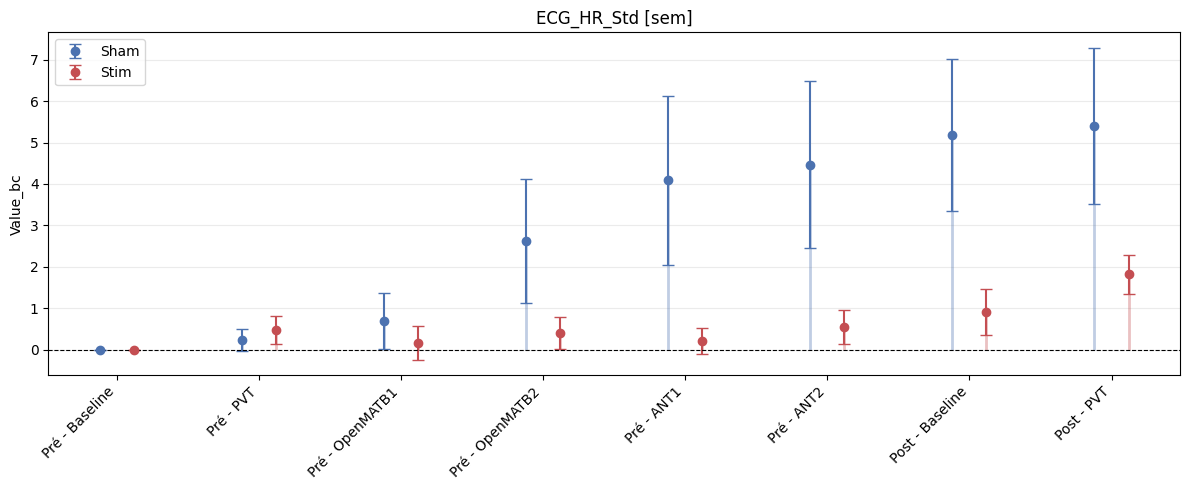

In [106]:
graphe_par_phase_2groupes(
    df_features,
    feature="ECG_HR_Std",
    signal=None,
    modalite="ECG",
    colonne_val="Value_bc",
    barre="sem"
)


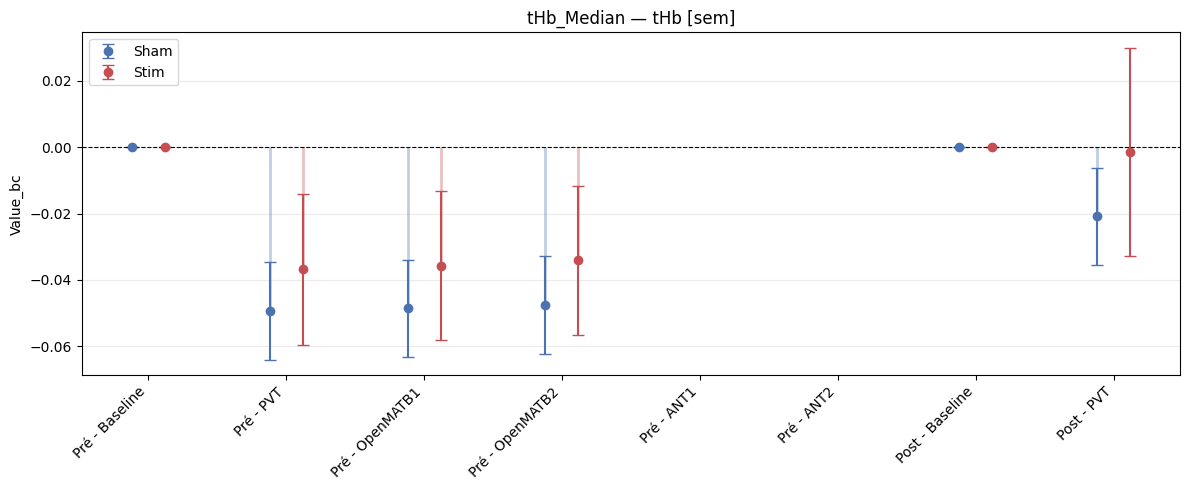

In [56]:
graphe_par_phase_2groupes(
    df_features,
    feature="tHb_Median",
    signal="tHb",
    modalite="fNIRS",
    colonne_val="Value_bc",
    barre="sem"
)


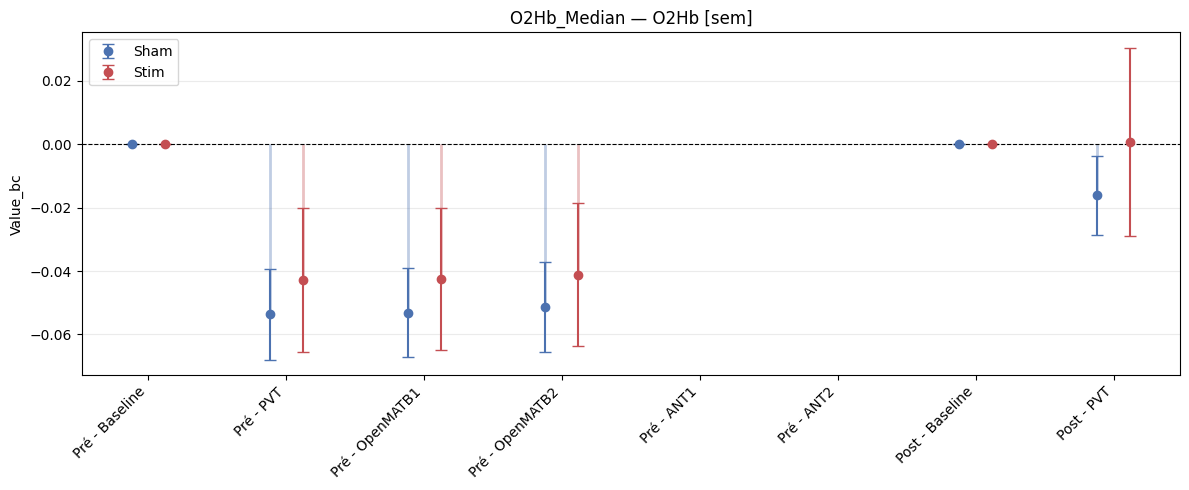

In [57]:
graphe_par_phase_2groupes(
    df_features,
    feature="O2Hb_Median",
    signal="O2Hb",
    modalite="fNIRS",
    colonne_val="Value_bc",
    barre="sem"
)


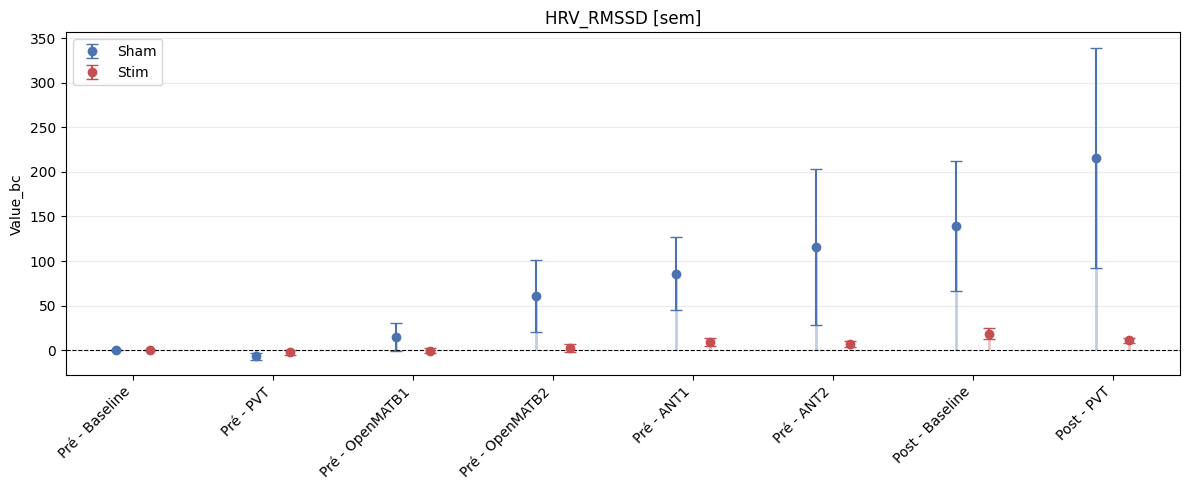

In [58]:
graphe_par_phase_2groupes(
    df_features,
    feature="HRV_RMSSD",
    modalite="ECG",
    colonne_val="Value_bc",
    barre="sem"
)


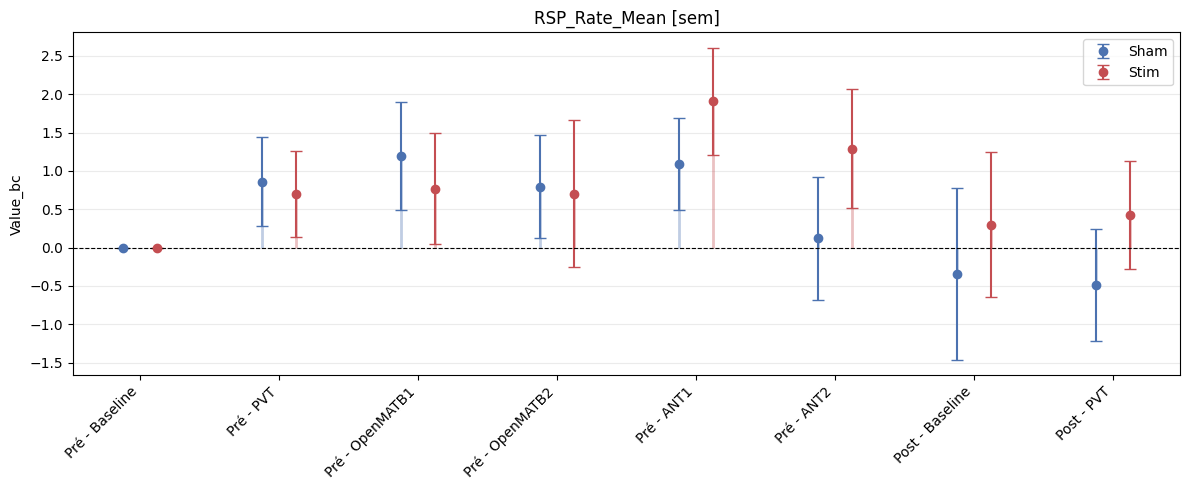

In [59]:
graphe_par_phase_2groupes(
    df_features,
    feature="RSP_Rate_Mean",
    modalite="RSP",
    colonne_val="Value_bc",
    barre="sem"
)


## 15. Heatmap features × phases

In [60]:
def heatmap_features_phases(df, modalite, colonne_val="Value_bc", groupe=None):
    s = df[df["Modalite"] == modalite].copy()

    if groupe is not None:
        s = s[s["Groupe"] == groupe]

    if s.empty:
        print(f"Aucune donnée pour {modalite}")
        return

    piv = (
        s.groupby(["Feature", "Phase"], observed=True)[colonne_val]
        .mean()
        .unstack("Phase")
    )

    cols = [p for p in ordre_phases if p in piv.columns]
    piv = piv[cols].dropna(how="all")

    # z-score par feature
    piv_z = piv.sub(piv.mean(axis=1), axis=0)
    piv_z = piv_z.div(piv.std(axis=1).replace(0, np.nan), axis=0)

    plt.figure(figsize=(12, max(4, 0.35 * len(piv_z))))

    sns.heatmap(
        piv_z,
        cmap="RdBu_r",
        center=0,
        cbar_kws={"label": f"{colonne_val} z-score par feature"}
    )

    titre = f"{modalite} — features × phases"
    if groupe is not None:
        titre += f" — groupe {groupe}"

    plt.title(titre)
    plt.tight_layout()
    plt.show()


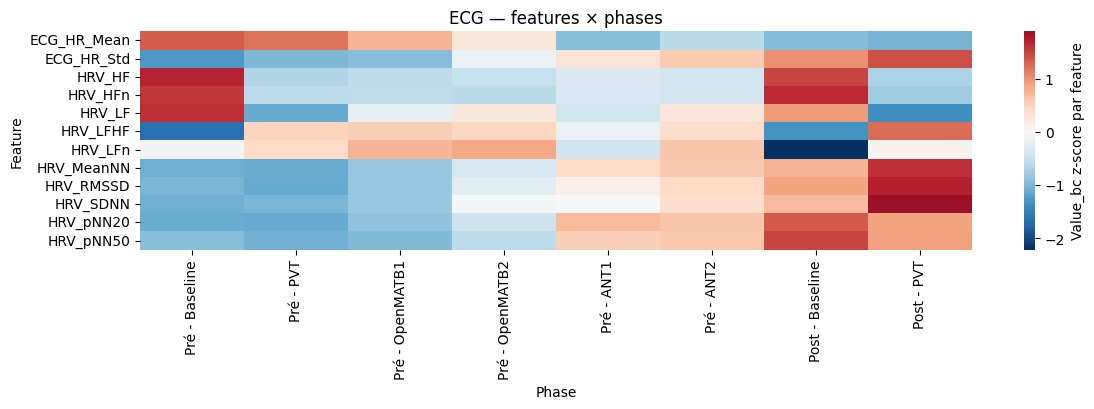

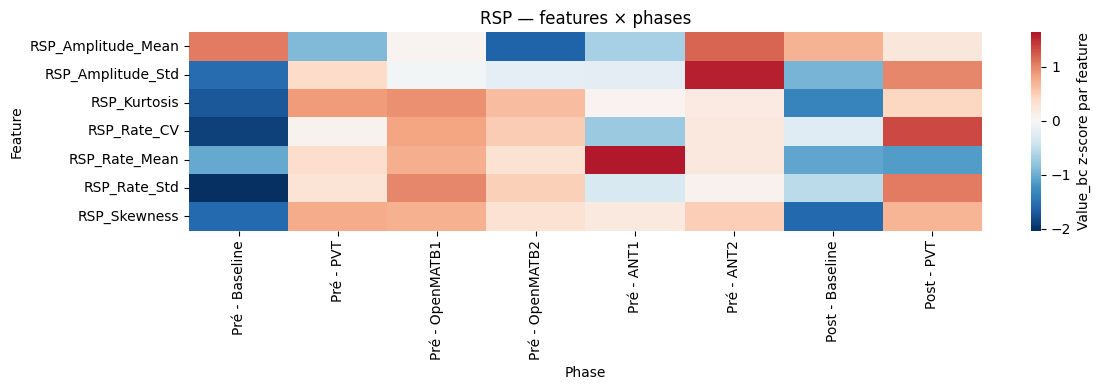

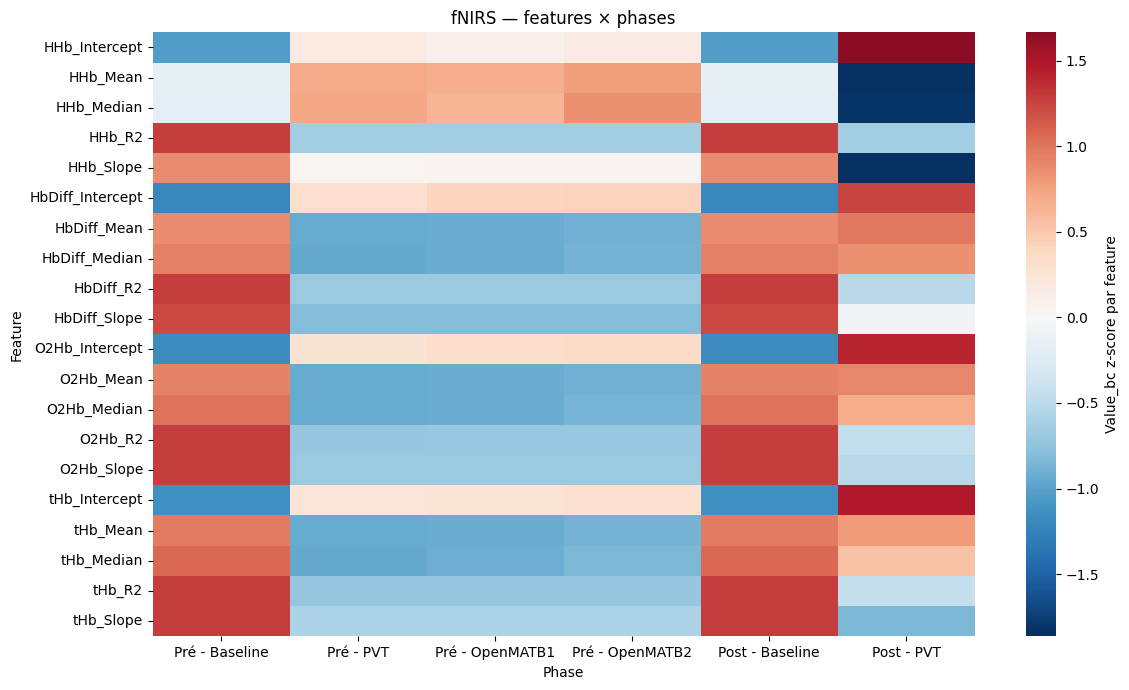

In [61]:
heatmap_features_phases(df_features, "ECG", "Value_bc")
heatmap_features_phases(df_features, "RSP", "Value_bc")
heatmap_features_phases(df_features, "fNIRS", "Value_bc")


## 16. Contrôle rapide cohérence source / fichiers

In [62]:
def resume_sources_et_fichiers(df_temps):
    lignes = []

    for _, row in df_temps.iterrows():
        num = int(row["Participant"])
        dossier = dico_dossiers_sh.get(num)

        lignes.append({
            "Participant": num,
            "Source_pre": row["Source_pre"],
            "Source_post": row["Source_post"],
            "Dossier_SH": pd.notna(dossier),
            "NIRS_pre_oxy": trouver_fichier_oxysoft(num, "pre") is not None,
            "NIRS_post_oxy": trouver_fichier_oxysoft(num, "post") is not None,
            "BriteLiteRaw": (Path(dossier) / "BriteLiteFrontalRaw.csv").exists() if dossier else False,
            "BioEcgRaw": (Path(dossier) / "BioEcgRaw.csv").exists() if dossier else False,
            "BioBreathingRaw": (Path(dossier) / "BioBreathingRaw.csv").exists() if dossier else False,
            "NIRS_preprocessed": (Path(dossier) / FICH_NIRS_OUT).exists() if dossier else False,
            "ECG_preprocessed": (Path(dossier) / FICH_ECG_OUT).exists() if dossier else False,
            "RSP_preprocessed": (Path(dossier) / FICH_RSP_OUT).exists() if dossier else False,
        })

    return pd.DataFrame(lignes)


df_controle = resume_sources_et_fichiers(df_temps)
df_controle.head()


,Participant,Source_pre,Source_post,Dossier_SH,NIRS_pre_oxy,NIRS_post_oxy,BriteLiteRaw,BioEcgRaw,BioBreathingRaw,NIRS_preprocessed,ECG_preprocessed,RSP_preprocessed
0,1,oxysoft,oxysoft,False,True,True,False,False,False,False,False,False
1,2,sensorhub,oxysoft,True,True,True,True,True,True,False,False,False
2,3,sensorhub,oxysoft,True,True,True,True,True,True,False,False,False
3,4,sensorhub,oxysoft,True,True,True,True,True,True,False,False,False
4,5,sensorhub,sensorhub,True,True,True,True,True,True,False,False,False


In [63]:
df_controle.to_excel("controle_sources_fichiers_v3.xlsx", index=False)


## 17. Corrélation canaux fNIRS

In [65]:
ORDRE_CANAUX = [
    "Rx1Tx1", "Rx1Tx3", "Rx2Tx1", "Rx2Tx3",
    "Rx3Tx4", "Rx3Tx5", "Rx4Tx4", "Rx4Tx5"
]

DOSSIER_FIGS_CORR = Path("Figures_correlation_intercanaux")
DOSSIER_FIGS_CORR.mkdir(parents=True, exist_ok=True)


In [66]:
def matrice_corr_intercanaux(df_nirs, t0=None, t1=None, bloc=None, signal="O2HB", method="pearson"):
    """
    signal : "O2HB", "HHB", "tHb", "HbDiff"
    """

    if df_nirs is None or "Time_ms" not in df_nirs.columns:
        return None

    sub = df_nirs.copy()

    if bloc is not None and "Bloc" in sub.columns:
        sub = sub[sub["Bloc"] == bloc].copy()

    if t0 is not None:
        sub = sub[sub["Time_ms"] >= t0]

    if t1 is not None:
        sub = sub[sub["Time_ms"] <= t1]

    if len(sub) < 30:
        return None

    data = {}

    for base in ORDRE_CANAUX:
        col_o2 = f"{base}O2HB"
        col_hh = f"{base}HHB"

        if signal.upper() == "O2HB":
            if col_o2 in sub.columns:
                data[base] = sub[col_o2].astype(float)

        elif signal.upper() == "HHB":
            if col_hh in sub.columns:
                data[base] = sub[col_hh].astype(float)

        elif signal.lower() == "thb":
            if col_o2 in sub.columns and col_hh in sub.columns:
                data[base] = sub[col_o2].astype(float) + sub[col_hh].astype(float)

        elif signal.lower() == "hbdiff":
            if col_o2 in sub.columns and col_hh in sub.columns:
                data[base] = sub[col_o2].astype(float) - sub[col_hh].astype(float)

    X = pd.DataFrame(data)

    if X.shape[1] < 2:
        return None

    return X.corr(method=method)


In [68]:
def heatmap_corr_intercanaux_participant(
    num,
    phase,
    signal="O2HB",
    method="pearson",
    annot=True,
    save=False
):
    df_nirs = dico_data.get(int(num), {}).get("fnirs")

    if df_nirs is None:
        print(f"⚠️ P{num} : pas de fNIRS prétraité")
        return

    if phase not in dico_phases_fnirs.get(int(num), {}):
        print(f"⚠️ P{num} : phase absente -> {phase}")
        return

    t0, t1 = dico_phases_fnirs[int(num)][phase]
    bloc = "pre" if phase.startswith("Pré") else "post"

    corr = matrice_corr_intercanaux(
        df_nirs,
        t0=t0,
        t1=t1,
        bloc=bloc,
        signal=signal,
        method=method
    )

    if corr is None:
        print(f"⚠️ P{num} {phase} : matrice impossible")
        return

    plt.figure(figsize=(7, 6))

    sns.heatmap(
        corr,
        vmin=-1,
        vmax=1,
        center=0,
        cmap="RdBu_r",
        square=True,
        annot=annot,
        fmt=".2f",
        linewidths=0.5,
        cbar_kws={"label": "Corrélation"}
    )

    plt.title(f"P{int(num):02d} — {phase} — {signal}")
    plt.tight_layout()

    if save:
        fname = f"P{int(num):02d}_{phase}_{signal}_corr.png"
        fname = fname.replace(" ", "_").replace("é", "e").replace("è", "e").replace("–", "-")
        plt.savefig(DOSSIER_FIGS_CORR / fname, dpi=300, bbox_inches="tight")

    plt.show()


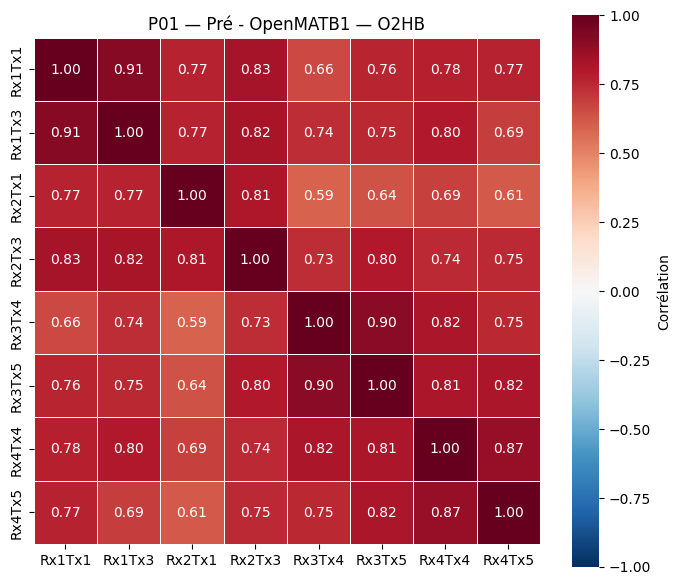

In [69]:
heatmap_corr_intercanaux_participant(
    num=1,
    phase="Pré - OpenMATB1",
    signal="O2HB",
    annot=True,
    save=True
)


In [70]:
def heatmaps_corr_participant(num, signal="O2HB", save=True):
    for phase in ordre_phases:
        if phase in dico_phases_fnirs.get(int(num), {}):
            heatmap_corr_intercanaux_participant(
                num=num,
                phase=phase,
                signal=signal,
                annot=False,
                save=save
            )


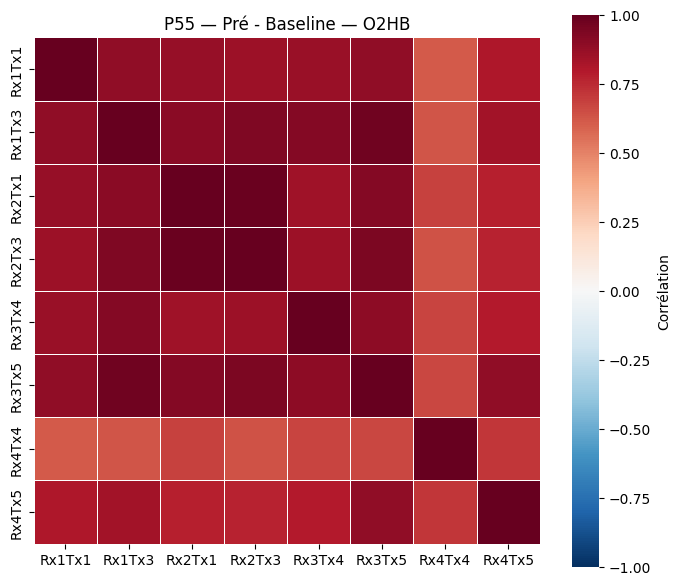

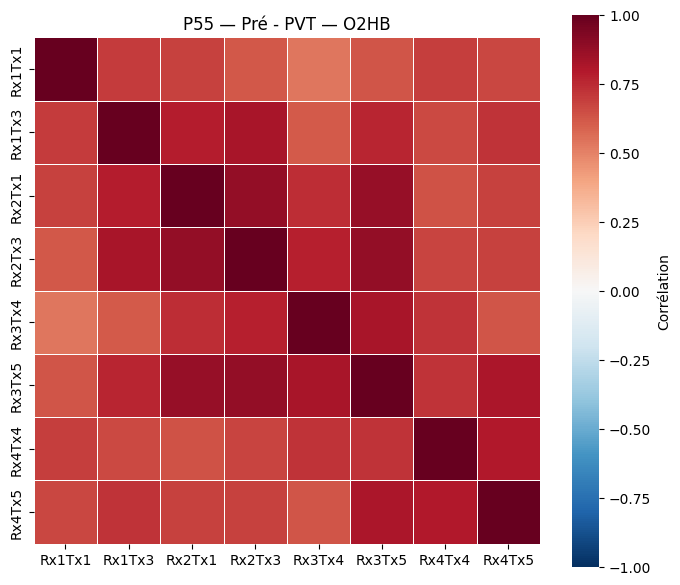

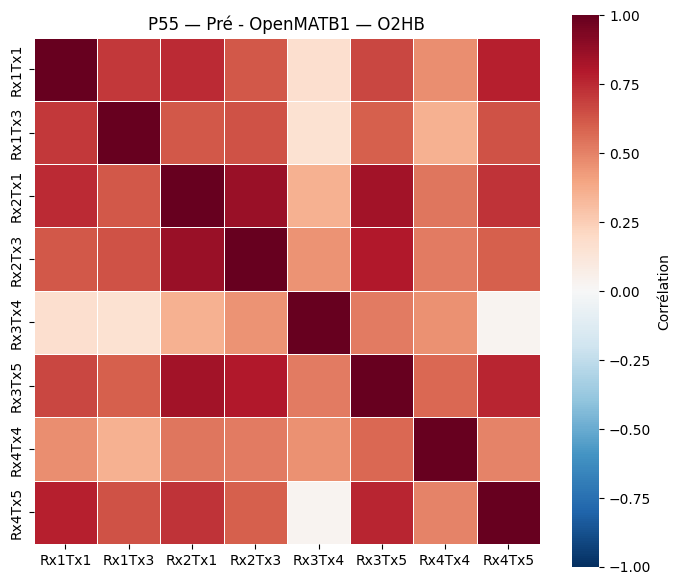

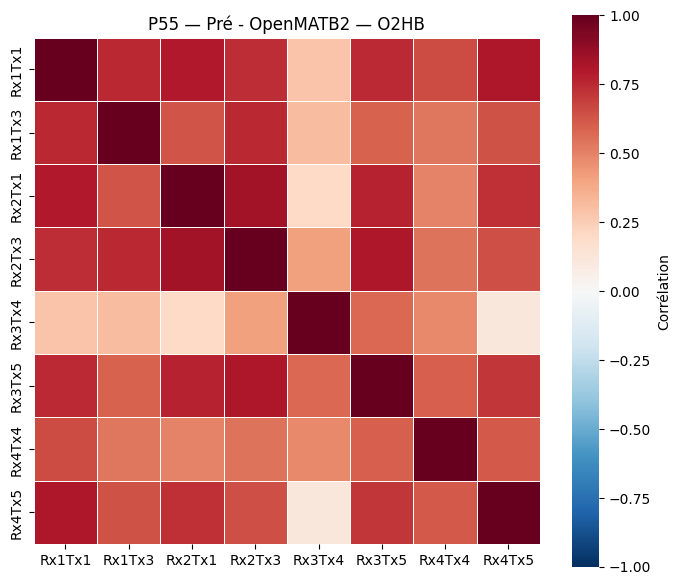

⚠️ P55 Pré - ANT1 : matrice impossible
⚠️ P55 Pré - ANT2 : matrice impossible


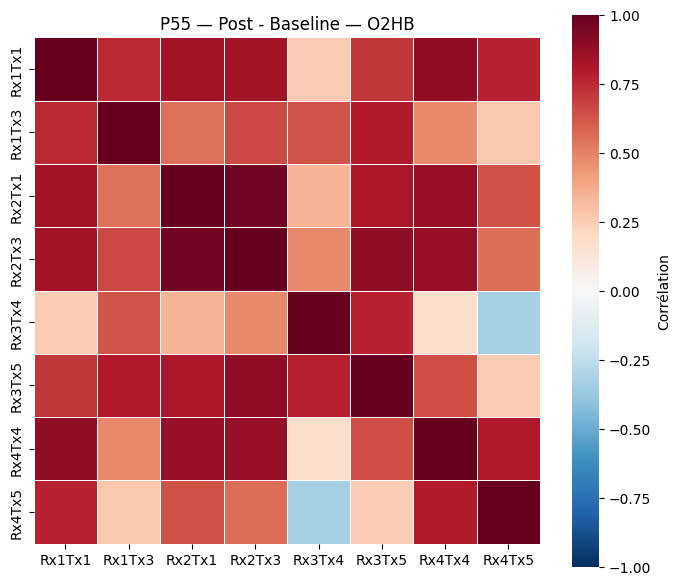

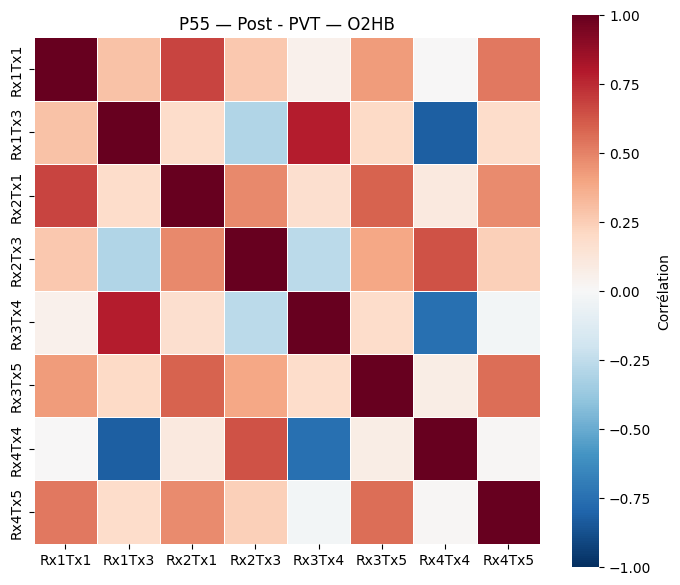

In [81]:
heatmaps_corr_participant(55, signal="O2HB", save=True)


In [72]:
def heatmap_corr_moyenne_groupe(
    phase,
    groupe,
    signal="O2HB",
    method="pearson",
    annot=True,
    save=False
):
    matrices = []

    participants = (
        df_features.loc[df_features["Groupe"] == groupe, "Participant"]
        .dropna()
        .astype(int)
        .unique()
    )

    for num in participants:
        df_nirs = dico_data.get(num, {}).get("fnirs")

        if df_nirs is None:
            continue

        if phase not in dico_phases_fnirs.get(num, {}):
            continue

        t0, t1 = dico_phases_fnirs[num][phase]
        bloc = "pre" if phase.startswith("Pré") else "post"

        corr = matrice_corr_intercanaux(
            df_nirs,
            t0=t0,
            t1=t1,
            bloc=bloc,
            signal=signal,
            method=method
        )

        if corr is not None:
            matrices.append(corr.reindex(index=ORDRE_CANAUX, columns=ORDRE_CANAUX))

    if len(matrices) == 0:
        print(f"⚠️ Aucune matrice pour groupe {groupe}, phase {phase}")
        return

    corr_mean = pd.concat(matrices).groupby(level=0).mean()
    corr_mean = corr_mean.reindex(index=ORDRE_CANAUX, columns=ORDRE_CANAUX)

    plt.figure(figsize=(7, 6))

    sns.heatmap(
        corr_mean,
        vmin=-1,
        vmax=1,
        center=0,
        cmap="RdBu_r",
        square=True,
        annot=annot,
        fmt=".2f",
        linewidths=0.5,
        cbar_kws={"label": "Corrélation moyenne"}
    )

    nom_groupe = NOMS_GROUPE.get(groupe, f"Groupe {groupe}")

    plt.title(f"{nom_groupe} — {phase} — {signal}")
    plt.tight_layout()

    if save:
        fname = f"Groupe_{groupe}_{phase}_{signal}_corr_moyenne.png"
        fname = fname.replace(" ", "_").replace("é", "e").replace("è", "e").replace("–", "-")
        plt.savefig(DOSSIER_FIGS_CORR / fname, dpi=300, bbox_inches="tight")

    plt.show()


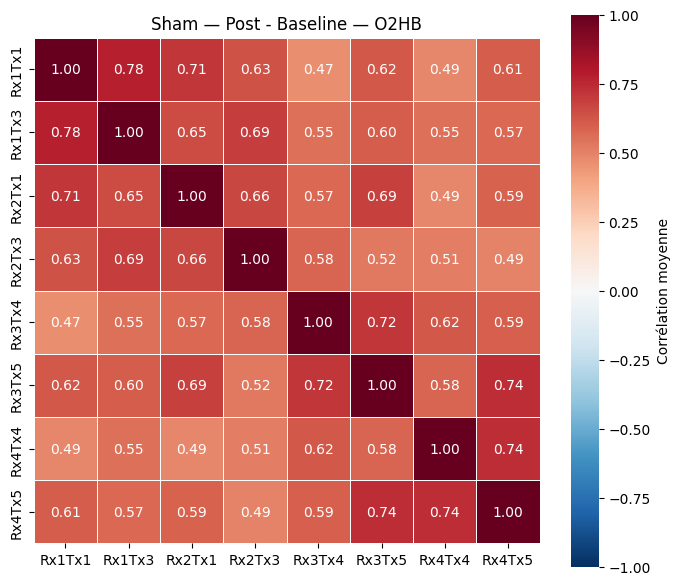

In [79]:
heatmap_corr_moyenne_groupe(
    phase="Post - Baseline",
    groupe=0,
    signal="O2HB",
    save=True
)

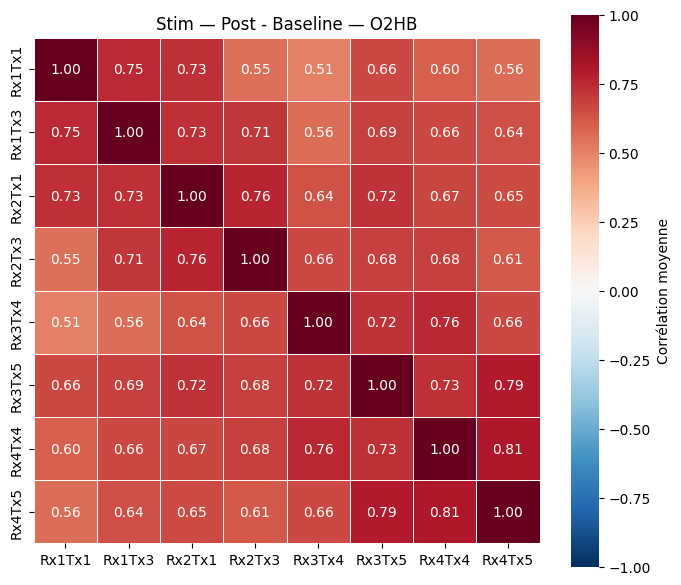

In [80]:
heatmap_corr_moyenne_groupe(
    phase="Post - Baseline",
    groupe=1,
    signal="O2HB",
    save=True
)

In [82]:
def heatmap_corr_tous_participants(
    phase=None,
    signal="O2HB",
    method="pearson",
    annot=True,
    save=False
):
    matrices = []
    participants_inclus = []

    for num in df_temps["Participant"].dropna().astype(int):
        df_nirs = dico_data.get(num, {}).get("fnirs")

        if df_nirs is None:
            continue

        if phase is None:
            corr = matrice_corr_intercanaux(
                df_nirs,
                signal=signal,
                method=method
            )
        else:
            if phase not in dico_phases_fnirs.get(num, {}):
                continue

            t0, t1 = dico_phases_fnirs[num][phase]
            bloc = "pre" if phase.startswith("Pré") else "post"

            corr = matrice_corr_intercanaux(
                df_nirs,
                t0=t0,
                t1=t1,
                bloc=bloc,
                signal=signal,
                method=method
            )

        if corr is not None:
            corr = corr.reindex(index=ORDRE_CANAUX, columns=ORDRE_CANAUX)
            matrices.append(corr)
            participants_inclus.append(num)

    if len(matrices) == 0:
        print("⚠️ Aucune matrice disponible.")
        return

    # Moyenne propre des corrélations avec transformation de Fisher
    stack = np.stack([m.values for m in matrices])
    stack = np.clip(stack, -0.999999, 0.999999)

    z = np.arctanh(stack)
    corr_mean = np.tanh(np.nanmean(z, axis=0))
    np.fill_diagonal(corr_mean, 1)

    corr_mean = pd.DataFrame(
        corr_mean,
        index=ORDRE_CANAUX,
        columns=ORDRE_CANAUX
    )

    plt.figure(figsize=(7, 6))

    sns.heatmap(
        corr_mean,
        vmin=-1,
        vmax=1,
        center=0,
        cmap="RdBu_r",
        square=True,
        annot=annot,
        fmt=".2f",
        linewidths=0.5,
        cbar_kws={"label": "Corrélation moyenne"}
    )

    titre = f"Tous participants — {signal}"
    if phase is not None:
        titre += f" — {phase}"

    plt.title(f"{titre}\nN = {len(participants_inclus)} participants")
    plt.tight_layout()

    if save:
        fname = f"Tous_participants_{signal}"
        if phase is not None:
            fname += f"_{phase}"

        fname = (
            fname.replace(" ", "_")
                 .replace("é", "e")
                 .replace("è", "e")
                 .replace("–", "-")
        )

        plt.savefig(DOSSIER_FIGS_CORR / f"{fname}.png", dpi=300, bbox_inches="tight")

    plt.show()

    return corr_mean, participants_inclus


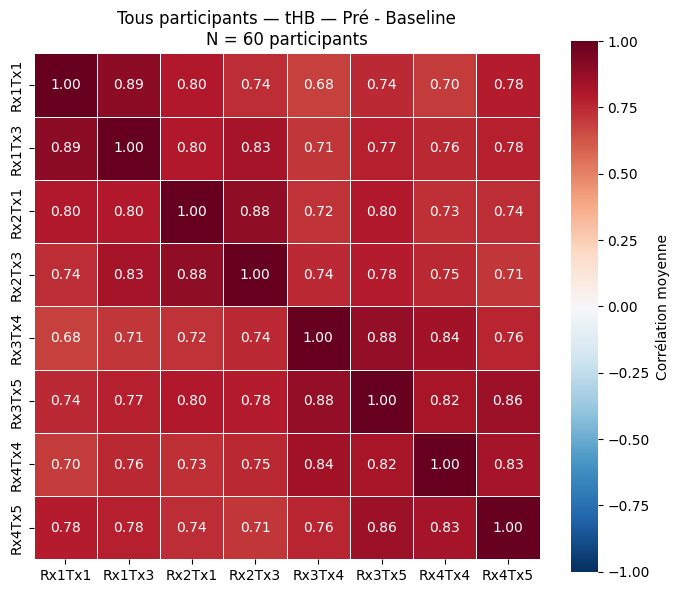

In [87]:
corr_all, participants_inclus = heatmap_corr_tous_participants(
    phase="Pré - Baseline",
    signal="tHB",
    annot=True,
    save=True
)

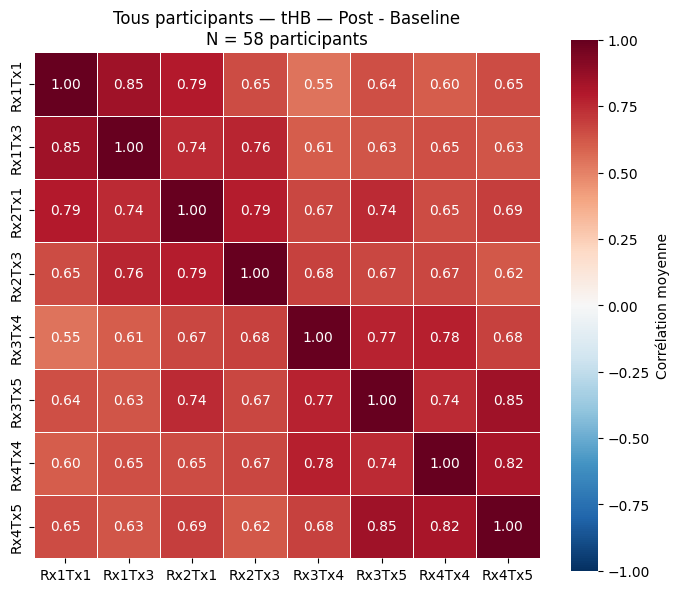

In [88]:
corr_all, participants_inclus = heatmap_corr_tous_participants(
    phase="Post - Baseline",
    signal="tHB",
    annot=True,
    save=True
)

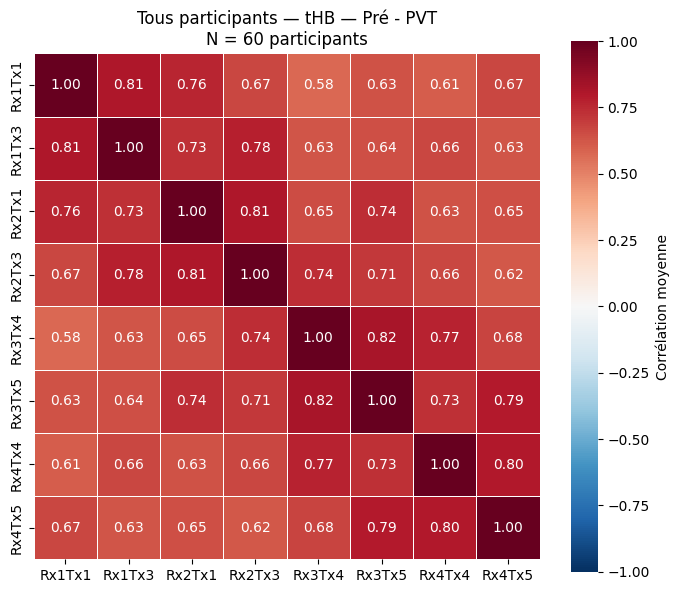

In [89]:
corr_all, participants_inclus = heatmap_corr_tous_participants(
    phase="Pré - PVT",
    signal="tHB",
    annot=True,
    save=True
)

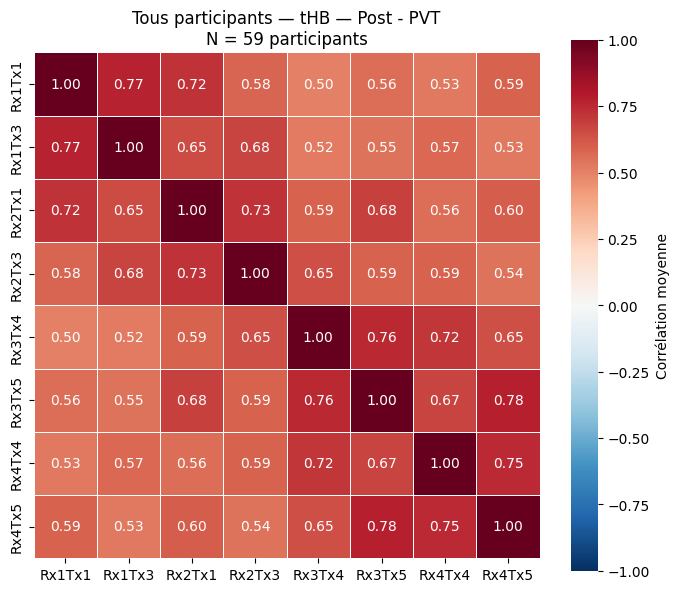

In [90]:
corr_all, participants_inclus = heatmap_corr_tous_participants(
    phase="Post - PVT",
    signal="tHB",
    annot=True,
    save=True
)